In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
from itertools import cycle
import os
from functools import partial

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Simulators.NoiseLevel import NoiseLevel
from halcyon.Simulators.SimulationResult import SimulationResult

from halcyon.Models.PhoenixModels import PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel

from halcyon.Models.ModelRunner import ModelRunner, run_training_job
from halcyon.Models.Losses import MSELossPlusMachineLearningL2

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

Check if MLFlow connects correctly

In [2]:
print(os.getenv("MLFLOW_TRACKING_URI"))

https://mlflow.cropresilience.org


In [3]:
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

# Input data

## Simulating

2026-02-17 12:03:29,885 - INFO - Generating network
2026-02-17 12:03:30,605 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_4*Node_3) + (Node_2)
my_network: Node_1: ~(Node_9*Node_5*Node_13~Node_0)
my_network: Node_2: (Node_4*Node_7) + (Node_1~Node_3) + (Node_0)
my_network: Node_3: (Node_2*Node_4) + (Node_7*Node_0)
my_network: Node_4: ~(Node_3*Node_7~Node_0) + (Node_2)
my_network: Node_5: (Node_11) + ~(Node_2*Node_1)
my_network: Node_6: ~(Node_9) + ~(Node_5) + ~(Node_12) + ~(Node_1)
my_network: Node_7: (Node_4*Node_0) + ~(Node_8~Node_3)
my_network: Node_8: ~(Node_2~Node_0) + (Node_7)
my_network: Node_9: ~(Node_1*Node_6)
my_network: Node_10: ~(Node_1)
my_network: Node_11: ~(Node_5) + ~(Node_1)
my_network: Node_12: (Node_9)
my_network: Node_13: ~(

🏃 View run dataset_genes20_sparsity0.1_nr_modules2_noiseALLNOISE at: https://mlflow.cropresilience.org/#/experiments/3/runs/cb55af6d44604c9395e9f3e9c5e54692
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-02-17 12:03:56,559 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_13*Node_24~Node_5) + (Node_4~Node_28) + ~(Node_2)
my_network: Node_1: ~(Node_11*Node_0*Node_8~Node_31)
my_network: Node_2: ~(Node_1) + (Node_6*Node_23) + ~(Node_3) + (Node_12) + ~(Node_7)
my_network: Node_3: (Node_30) + (Node_2*Node_12~Node_7) + ~(Node_6*Node_23)
my_network: Node_4: (Node_1*Node_9~Node_0~Node_5) + ~(Node_28)
my_network: Node_5: ~(Node_13*Node_0~Node_4) + (Node_29)
my_network: Node_6: (Node_2) + ~(Node_25*Node_17*Node_12~Node_3~Node_35~Node_7)
my_network: Node_7: ~(Node_17) + (Node_3) + ~(Node_2) + ~(Node_37)
my_network: Node_8: ~(Node_1~Node_15)
my_network: Node_9: (Node_18)
my_network: Node_10: ~(Node_39*Node_22~Node_0)
my_network: Node_11: (Node_1*Node_15

🏃 View run dataset_genes50_sparsity0.1_nr_modules5_noiseALLNOISE at: https://mlflow.cropresilience.org/#/experiments/3/runs/20ac828ac40844cdb32526682c0d21c5
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-02-17 12:04:16,080 - INFO - Generating network
2026-02-17 12:04:17,208 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_63*Node_24~Node_19) + ~(Node_2*Node_5)
my_network: Node_1: ~(Node_32*Node_74~Node_3) + ~(Node_0~Node_42) + ~(Node_15*Node_8) + (Node_16*Node_11)
my_network: Node_2: (Node_0*Node_3*Node_6~Node_1) + ~(Node_23~Node_7) + ~(Node_31~Node_43)
my_network: Node_3: (Node_23) + (Node_9*Node_8~Node_55) + (Node_2) + ~(Node_7~Node_19)
my_network: Node_4: ~(Node_28*Node_13~Node_29) + ~(Node_9) + ~(Node_56*Node_1)
my_network: Node_5: ~(Node_24*Node_19) + ~(Node_0)
my_network: Node_6: ~(Node_7*Node_2~Node_43) + (Node_10~Node_55) + ~(Node_61) + ~(Node_3~Node_21)
my_network: Node_7: (Node_23) + (Node_0*Node_2) + (Node_6) + ~(Node_3)
my_netwo

🏃 View run dataset_genes100_sparsity0.1_nr_modules10_noiseALLNOISE at: https://mlflow.cropresilience.org/#/experiments/3/runs/d03e0d627633471fa8f99ffebd9b4bb4
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-02-17 12:05:14,097 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_57*Node_5*Node_118*Node_2) + (Node_21*Node_276*Node_19~Node_35) + ~(Node_3*Node_17~Node_71) + (Node_165)
my_network: Node_1: (Node_222*Node_158*Node_0*Node_270~Node_31) + (Node_45*Node_182) + ~(Node_133*Node_61*Node_64*Node_51) + ~(Node_9)
my_network: Node_2: ~(Node_0*Node_3~Node_6) + ~(Node_1*Node_43*Node_83*Node_111) + (Node_79) + (Node_8*Node_24*Node_25) + (Node_152) + (Node_346)
my_network: Node_3: (Node_39~Node_248) + ~(Node_7*Node_5~Node_11) + ~(Node_114)
my_network: Node_4: ~(Node_9*Node_82*Node_115*Node_119) + (Node_67*Node_36~Node_118) + (Node_45) + ~(Node_1*Node_75*Node_66~Node_114)
my_network: Node_5: ~(Node_42*Node_2*Node_57~Node_67) + (Node_52*Node_457~Node_22) 

🏃 View run dataset_genes500_sparsity0.1_nr_modules50_noiseALLNOISE at: https://mlflow.cropresilience.org/#/experiments/3/runs/6d730ccc697642a6b1cfa631dbb16f49
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


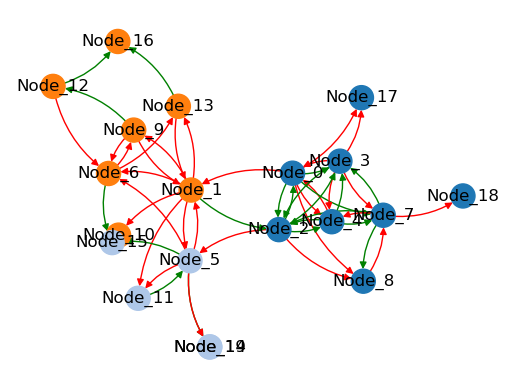

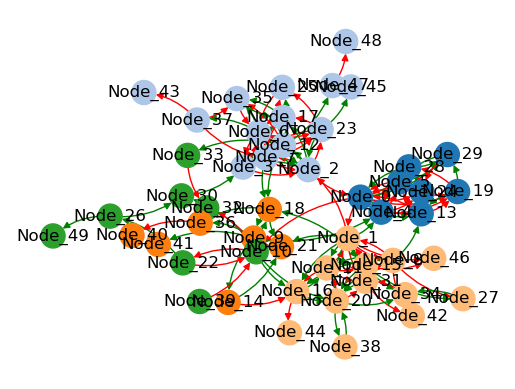

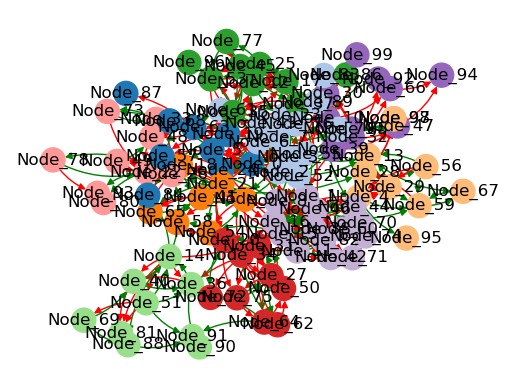

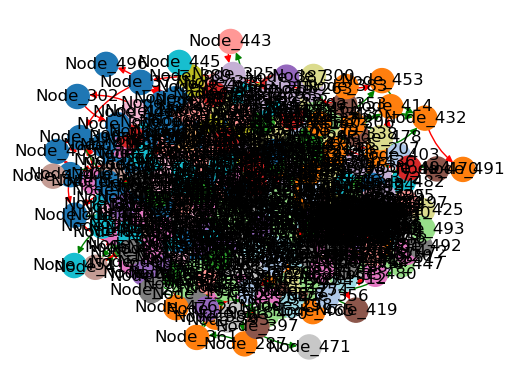

In [4]:
nr_genes_list =   [20, 50, 100, 500]
nr_modules_list = [2,  5,  10,  50 ]
sparsity_list = [0.1]
keep_self_interactions = False
out_path = Path("../data/datasets_for_mlflow_logging") 
settings_path = Path("../setting_files/gnw_testing_runs_settings.txt")

sim_outputs: list[SimulationResult] = []
for nr_genes, nr_modules in zip(nr_genes_list, nr_modules_list): 
    for sparsity in sparsity_list: 
        gnw_sim = GNWSimRunner(
            settings_path=settings_path,
        )
        
        generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
        generated_data_path.mkdir(parents=True, exist_ok=True)
        network_name = 'my_network'
        sim_output = gnw_sim.run_simulation(
            n_genes=nr_genes,
            sparsity=sparsity,
            num_modules=nr_modules,
            network_name=network_name,
            output_path=generated_data_path,
            keep_self_interactions=keep_self_interactions,
            noise_level=NoiseLevel.ALLNOISE,
        )

        sim_output.network.do_clustering()
        assert number_weakly_connected_components(sim_output.network._graph) == 1, "The generated network is not fully connected."
        
        sim_output.network.plot()
        fig_path = generated_data_path / "network_plot.png"
        plt.savefig(fig_path)

        sim_output.save_to_pkl(generated_data_path / "simulation_result.pkl")
        
        with mlflow.start_run(run_name=f"dataset_genes{nr_genes}_sparsity{sparsity}_nr_modules{nr_modules}_noise{NoiseLevel.ALLNOISE.name}"):
            mlflow.set_tag("run_type", "dataset")
            mlflow.log_params({
                "nr_genes": nr_genes,
                "sparsity": sparsity,
                "num_modules": nr_modules,
                "noise_level": NoiseLevel.ALLNOISE.name,
                "seed": seed,
            })
            mlflow.log_artifacts(generated_data_path, artifact_path="dataset")
            mlflow.log_artifact(settings_path)
                

## Downloading data from MLFlow

In [ ]:
sim_run_id_to_use = "72e5027402c2484db8acade9e9872170"  
run = mlflow.get_run(sim_run_id_to_use)

params = run.data.params
print(params)

In [ ]:
ml_flow_download_path = mlflow.artifacts.download_artifacts(run_id=sim_run_id_to_use, artifact_path="dataset")
sim_output = SimulationResult.load_from_pkl(Path(ml_flow_download_path) / "simulation_result.pkl")

## Convert sim output into datasets for use with the trainer object

In [ ]:
# From sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = sim_output.create_datasets()
dataset_dict = {
    "single_ko": single_ko_dataset,
    "double_ko": double_ko_dataset,}

# Trainers (with different models) creation

In [ ]:
train_jobs : list[ModelRunner] = []
device = cycle(['cuda:0', 'cuda:1'])

## Mech model

Assigning only one cluster of genes to this MM

In [ ]:
sim_output.network.do_clustering()

print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [ ]:
node_that_should_be_in_model = 'Node_18'
for i, module in enumerate(sim_output.network._clustering):
    if node_that_should_be_in_model in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break

Generate MM from this subset

In [ ]:
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=[], from_gnw=True, device=next(device))
# Select only genes from specific module and set timescaler
mm.select_genes(genes_to_select, 
                goldstandard_signed_file_for_expression_substitution = sim_output.data_path / f'{sim_output.network_name}_goldstandard_signed.tsv')
mm.set_timescaler(time_scaling_factor)

print(mm.modelled_gene_labels)

# Creating MM trainer even though it cannot be trained
mm_trainer = ModelRunner(
    mm,
    nr_epochs=0,
    batch_size=32,
)

train_jobs.append(mm_trainer)

## ML and Hybrid model

In [ ]:
for hidden_size in [10, 20]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=single_ko_dataset.genes,
                    hidden_size=hidden_size,
                    condition_names=single_ko_dataset.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device=next(device)
            )

        # Create hybrid model with MM and with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device=next(device))
        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            model_runner = ModelRunner(
                model = model,
                batch_size=32,
                nr_epochs=5,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(model_runner)

## Baseline model (always derivative of 0)

In [ ]:
baseline_model = AlwaysDerivativeZero(
    modelled_gene_labels=single_ko_dataset.genes,
    condition_names=single_ko_dataset.all_environments
    )

baseline_trainer = ModelRunner(
    baseline_model,
    batch_size=8,
    nr_epochs=0,
)
train_jobs.append(baseline_trainer)

In [ ]:
for job in train_jobs:
    print(job)
    print()

In [ ]:
len(train_jobs)

In [ ]:
# Old debugging / development bits
# train_jobs[1].nr_epochs = 0
# train_jobs[1].train_and_predict_for_mlflow(dataset_dict, 'single_ko', sim_run_id_to_use)

# Do training

In [ ]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(
        partial(
            run_training_job, 
            dataset_dict=dataset_dict, 
            train_data_key_in_dict="single_ko", 
            simulation_parent_id=sim_run_id_to_use, 
            do_mlflow_model_logging=False,
        ),
        train_jobs
    )

# All files have now been logged to MLFlow

To see how to process this data further look into the MLFlow loading and plotting notebook(s)